# Garantias sob deriva

Com a regra congelada em 2022, o X2 acompanha G1 e G2 trimestre a trimestre de 2023 a 2025. O X3 refaz esses trimestres
com as sete estratégias de atualização, de (a) a (g), e o X4 leva a comparação para a pandemia; no fim, a tabela das
hipóteses exploratórias junta os três. Os resultados estão em `reports/exploratorios/morte/nenhuma/`
(`resultados_x2.json`, `resultados_x3.json`, `resultados_x4.json` e `resumo.json`), e as figuras, em
`reports/figures/morte/`.

In [1]:
import json

import pandas as pd
from IPython.display import Image

from triagem_baixo_risco import config
from triagem_baixo_risco.modeling.predict import holm
from triagem_baixo_risco.plots import LABELS

EXPLORATORIOS = config.REPORTS_DIR / "exploratorios" / "morte" / "nenhuma"
FIGURAS = config.FIGURES_DIR / "morte"
pd.set_option("display.max_colwidth", None)


def pct(x, casas=2):
    return f"{100 * x:.{casas}f}%".replace(".", ",")


def num(x, casas=0):
    # 1234567.891 com casas=2 vira "1.234.567,89"
    return f"{x:,.{casas}f}".replace(",", " ").replace(".", ",").replace(" ", ".")


def pv(p):
    return "< 0,0001" if p < 0.0001 else num(p, 4)


def ler(nome):
    return json.loads((EXPLORATORIOS / f"{nome}.json").read_text())


x2, x3, x4, resumo = ler("resultados_x2"), ler("resultados_x3"), ler("resultados_x4"), ler("resumo")

## A calibração de 2022 envelhecendo

No X2, o boosting foi treinado com as internações de 2019 a 2021 e calibrado com as de 2022, com α = 0,05, e a regra não
muda mais. A FDL é a fração dos óbitos do trimestre que a regra liberou; a TOL, a taxa de óbito entre as internações
liberadas, que G2 compara com o r̂. As colunas com Holm corrigem os 12 trimestres juntos, como nos critérios de H1 e H2.

In [2]:
def por_trimestre(linhas):
    t = pd.DataFrame(linhas).set_index("trimestre")
    return pd.DataFrame(
        {
            "internações": t["n"].map(num),
            "razão de prevalência": t["razao_prevalencia"].map(lambda v: num(v, 2)),
            "liberadas": t["fracao_liberada"].map(lambda v: pct(v, 1)),
            "óbitos liberados": t["fdl_k"].map(num) + " de " + t["fdl_n"].map(num),
            "FDL": t["fdl"].map(pct),
            "p G1": t["p_g1"].map(pv),
            "p G1, Holm": pd.Series(holm(t["p_g1"])["p_adjusted"], index=t.index).map(pv),
            "TOL": t["tol"].map(pct),
            "r̂": t["r_hat"].map(pct),
            "p G2, Holm": pd.Series(holm(t["p_g2"])["p_adjusted"], index=t.index).map(pv),
            "O/E": t["oe"].map(lambda v: num(v, 2)),
        }
    )


por_trimestre(x2)

,internações,razão de prevalência,liberadas,óbitos liberados,FDL,p G1,"p G1, Holm",TOL,r̂,"p G2, Holm",O/E
trimestre,,,,,,,,,,,
2023T1,30.399,"0,95","65,1%",72 de 1.363,"5,28%","0,3565","1,0000","0,36%","0,42%","1,0000","0,97"
2023T2,31.666,"0,89","65,5%",80 de 1.331,"6,01%","0,0950","0,9499","0,39%","0,42%","1,0000","0,93"
2023T3,32.687,"0,88","65,7%",73 de 1.344,"5,43%","0,2862","1,0000","0,34%","0,42%","1,0000","0,92"
2023T4,32.625,"0,94","65,5%",95 de 1.445,"6,57%","0,0194","0,2137","0,44%","0,42%","1,0000","0,97"
2024T1,34.265,"0,85","66,3%",102 de 1.363,"7,48%","0,0009","0,0113","0,45%","0,42%","1,0000","0,89"
2024T2,37.449,"0,80","67,1%",80 de 1.404,"5,70%","0,1766","1,0000","0,32%","0,42%","1,0000","0,85"
2024T3,36.380,"0,89","65,0%",83 de 1.519,"5,46%","0,2624","1,0000","0,35%","0,42%","1,0000","0,90"
2024T4,34.777,"0,83","64,4%",69 de 1.362,"5,07%","0,4706","1,0000","0,31%","0,42%","1,0000","0,83"
2025T1,34.194,"0,85","63,4%",74 de 1.371,"5,40%","0,3003","1,0000","0,34%","0,42%","1,0000","0,81"


A regra liberou entre 63,4% e 67,1% das internações em todos os trimestres. A FDL passou de 5% em nove dos doze, mas só
2024T1 resiste à correção: 102 dos 1.363 óbitos foram liberados, 7,48%, com p = 0,0009 e 0,0113 depois de Holm. Sem
correção, 2023T4 também ficaria abaixo de 0,05, com p = 0,0194.

Nove trimestres acima de 5% não bastam para dizer que G1 falhou. A FDL da regra congelada depende de quais óbitos caíram
na parte B da calibração de 2022, e os doze trimestres herdam o mesmo sorteio; é essa variação que o teste beta-binomial
leva em conta, e o notebook 7.0 mostra quanto o binomial erraria sem ela.

A TOL passou do r̂ de 0,42% em 2023T4 e 2024T1, sem significância. Já o O/E caiu de 0,97 para 0,75, acompanhando a queda
da mortalidade: em 2025, o modelo previa bem mais óbitos do que houve.

## O 1º trimestre de 2024

H1b tira da FDL os óbitos de diagnósticos em surto: CID de 3 caracteres com pelo menos 10 óbitos no trimestre e pelo
menos 3 vezes o número esperado pela participação que tinham entre os óbitos dos 12 meses que terminam 3 meses antes do
início do trimestre. No X2, três trimestres tiveram algum código em surto.

In [3]:
t = pd.DataFrame(x2).set_index("trimestre")
surto = t[t["cids_em_surto"].map(len) > 0]
pd.DataFrame(
    {
        "CID em surto": surto["cids_em_surto"].map(", ".join),
        "óbitos com o CID": surto["fdl_n"] - surto["fdl_sem_surto_n"],
        "liberados com o CID": surto["fdl_k"] - surto["fdl_sem_surto_k"],
        "FDL": surto["fdl"].map(pct),
        "sem o CID": surto["fdl_sem_surto_k"].map(num) + " de " + surto["fdl_sem_surto_n"].map(num),
        "FDL sem o CID": surto["fdl_sem_surto"].map(pct),
        "p G1 sem o CID": surto["p_g1_sem_surto"].map(pv),
    }
)

,CID em surto,óbitos com o CID,liberados com o CID,FDL,sem o CID,FDL sem o CID,p G1 sem o CID
trimestre,,,,,,,
2023T3,I44,10,1,"5,43%",72 de 1.334,"5,40%","0,3024"
2024T1,A90,23,23,"7,48%",79 de 1.340,"5,90%","0,1215"
2024T2,J12,11,0,"5,70%",80 de 1.393,"5,74%","0,1623"


Os resultados salvos guardam só os óbitos do código em surto. Para ver também os da dengue hemorrágica, o A91, refaço
abaixo o modelo e a regra do X2, com a mesma semente, e confiro que 2024T1 volta com os mesmos 102 óbitos liberados em
1.363.

In [4]:
from triagem_baixo_risco.dataset import in_window, load_open
from triagem_baixo_risco.experimentos.exploratorios import X3_SETUP, predict_raw, prepare
from triagem_baixo_risco.modeling.predict import apply_rule
from triagem_baixo_risco.modeling.train import fit_window

dados = prepare(load_open(config.OPEN_DATA))
p_raw = predict_raw(dados, in_window(dados.dates, *X3_SETUP["train"]))
regra = fit_window(p_raw, dados.y, in_window(dados.dates, *X3_SETUP["base"]), kind=dados.calibrator)
tri = in_window(dados.dates, "2024-01-01", "2024-04-01")
liberada = apply_rule(regra.rule, regra.calibrate(p_raw[tri]))
obitos = pd.DataFrame({"CID": dados.codes[tri], "liberado": liberada})[dados.y[tri] == 1]
print("óbitos liberados em 2024T1:", num(obitos["liberado"].sum()), "de", num(len(obitos)))
dengue = obitos[obitos["CID"].isin(["A90", "A91"])]
dengue.groupby("CID")["liberado"].agg(óbitos="size", liberados="sum")

óbitos liberados em 2024T1: 102 de 1.363


,óbitos,liberados
CID,,
A90,23,23
A91,7,0


Em 2024T1, o código em surto foi o A90, a dengue, e os 23 pacientes que morreram com esse diagnóstico foram todos
liberados pela regra. Contando também os 7 óbitos com o A91, a dengue hemorrágica, que ficou fora do surto e não teve
óbito liberado, foram 30 óbitos por dengue no trimestre. Tirando o A90, sobram 79 óbitos liberados em 1.340, uma FDL de 5,90% com p = 0,1215, e o trimestre
deixa de violar G1.

Nos outros dois surtos, a regra liberou 1 óbito de I44, em 2023T3, e nenhum de J12, em 2024T2.

## Estratégias de atualização

O X3 repete os trimestres do X2 com sete maneiras de atualizar a regra, e a (a) é a própria estática. Duas recalibram
uma vez por ano, com o ano anterior: a (b) e a (d), que antes retreina o modelo com os anos anteriores. A trimestral (c)
usa os 12 meses que terminam 3 meses antes de cada trimestre, o atraso com que o SIH publica as AIH, e a janela suave
(f) usa todo o histórico disponível, com pesos que caem pela metade a cada 4 trimestres. O conformal adaptativo (e) fica
com a calibração de 2022 e ajusta o α a cada trimestre pela FDL de dois trimestres antes, a última com desfecho
conhecido. Já a (g) mantém as decisões da estática e só corrige as probabilidades e o r̂ pela prevalência estimada sem
rótulos.

Nas tabelas, as linhas com γ e meia-vida são variantes de parâmetro de (e) e (f), e as colunas de trimestres violados
contam só o que resiste a Holm.

In [5]:
def rotulo(chave):
    estrategia, _, variante = chave.partition("(")
    variante = variante.rstrip(")").replace("gamma", "γ").replace("meia_vida", "meia-vida").replace(".", ",")
    return LABELS[estrategia] + (f", {variante}" if variante else "")


def por_estrategia(experimento, resultados):
    hip = resumo["hipoteses_exploratorias"]
    tabela = {}
    for chave, linhas in resultados.items():
        cenario = f"{experimento}_{chave}"
        r = resumo["resumo_estrategias"][cenario]
        k, n = sum(x["fdl_k"] for x in linhas), sum(x["fdl_n"] for x in linhas)
        # as variantes de parâmetro ficam fora das hipóteses e não têm o teste do agregado
        agregado = {h: hip[h]["cenarios"].get(cenario, {}).get("agregado") for h in ("h1", "h1b")}
        tabela[rotulo(chave)] = {
            "|O/E - 1| médio": num(r["oe_desvio_medio"], 3),
            "trimestres com G1 violada": r["trimestres_g1_violada"],
            "trimestres com G2 violada": r["trimestres_g2_violada"],
            "liberadas, média": pct(r["fracao_liberada_media"], 1),
            "FDL agregada": pct(k / n),
            "p do agregado": pv(agregado["h1"]["p_violacao"]) if agregado["h1"] else "-",
            "p do agregado sem surtos": pv(agregado["h1b"]["p_violacao"]) if agregado["h1b"] else "-",
        }
    return pd.DataFrame(tabela).T.rename_axis("estratégia")


por_estrategia("x3", x3)

,|O/E - 1| médio,trimestres com G1 violada,trimestres com G2 violada,"liberadas, média",FDL agregada,p do agregado,p do agregado sem surtos
estratégia,,,,,,,
(a) estática,"0,124",1,0,"65,1%","5,46%","0,1573","0,2310"
(b) anual,"0,066",0,0,"63,9%","4,83%","0,6379","0,7431"
(c) trimestral com atraso,"0,059",0,0,"63,9%","4,89%","0,5758","0,6860"
(d) retreino anual,"0,067",0,0,"64,5%","4,80%","0,6631","0,7250"
(e) conformal adaptativo,"0,124",1,0,"64,9%","5,37%","0,2064","0,2926"
(f) janela suave,"0,070",0,0,"64,2%","4,93%","0,5691","0,7013"
(g) correção de prevalência,"1,052",1,7,"65,1%","5,46%","0,1573","0,2310"
"(e) conformal adaptativo, γ=0,01","0,124",1,0,"65,0%","5,42%",-,-
"(e) conformal adaptativo, γ=0,05","0,124",1,0,"64,8%","5,35%",-,-


Recalibrar melhorou o O/E: o |O/E - 1| médio caiu de 0,124 na estática para 0,059 na trimestral. As quatro estratégias
que recalibram, (b), (c), (d) e (f), terminaram sem trimestre com G1 violada e com FDL agregada abaixo de 5%, entre
4,80% e 4,93%. Com a (e), a FDL agregada quase não mudou (5,37%, contra 5,46% da estática), e a violação de 2024
continuou. A (g) foi o pior caso para G2: com as mesmas decisões da estática, a correção de prevalência levou o |O/E -
1| médio a 1,052 e deixou sete trimestres com G2 violada.

Os 5,46% agregados da estática dão p = 0,1573 no teste de G1, e sem os óbitos em surto, p = 0,2310. Antes do ETL de
2026, que acrescentou AIH de internações de 2025 cobradas em competências de 2026, esses dois p eram de 0,14 e 0,20.

Na figura, a estática é a linha mais grossa. O painel do meio mostra a TOL menos o r̂, e acima de zero a taxa de óbito
entre as liberadas passou do limite.

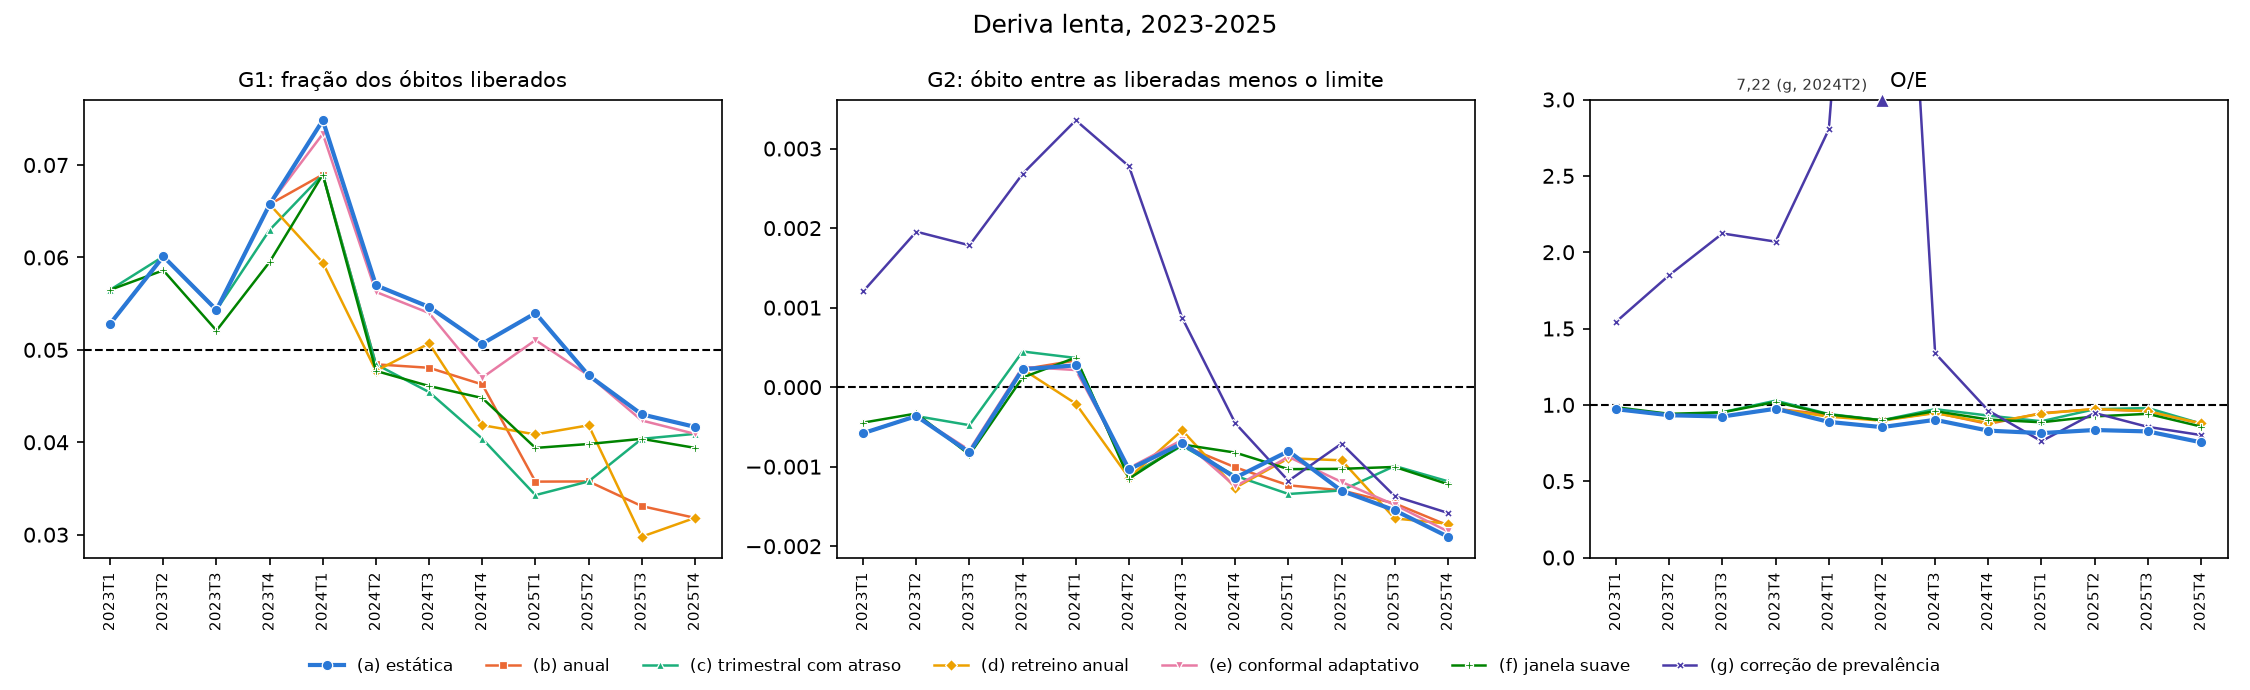

In [6]:
Image(filename=FIGURAS / "garantias_x3.png")

As variantes de γ e de meia-vida mudam pouco o quadro. A exceção é a janela suave com meia-vida de 8 trimestres, que
fica com um trimestre de G1 violada.

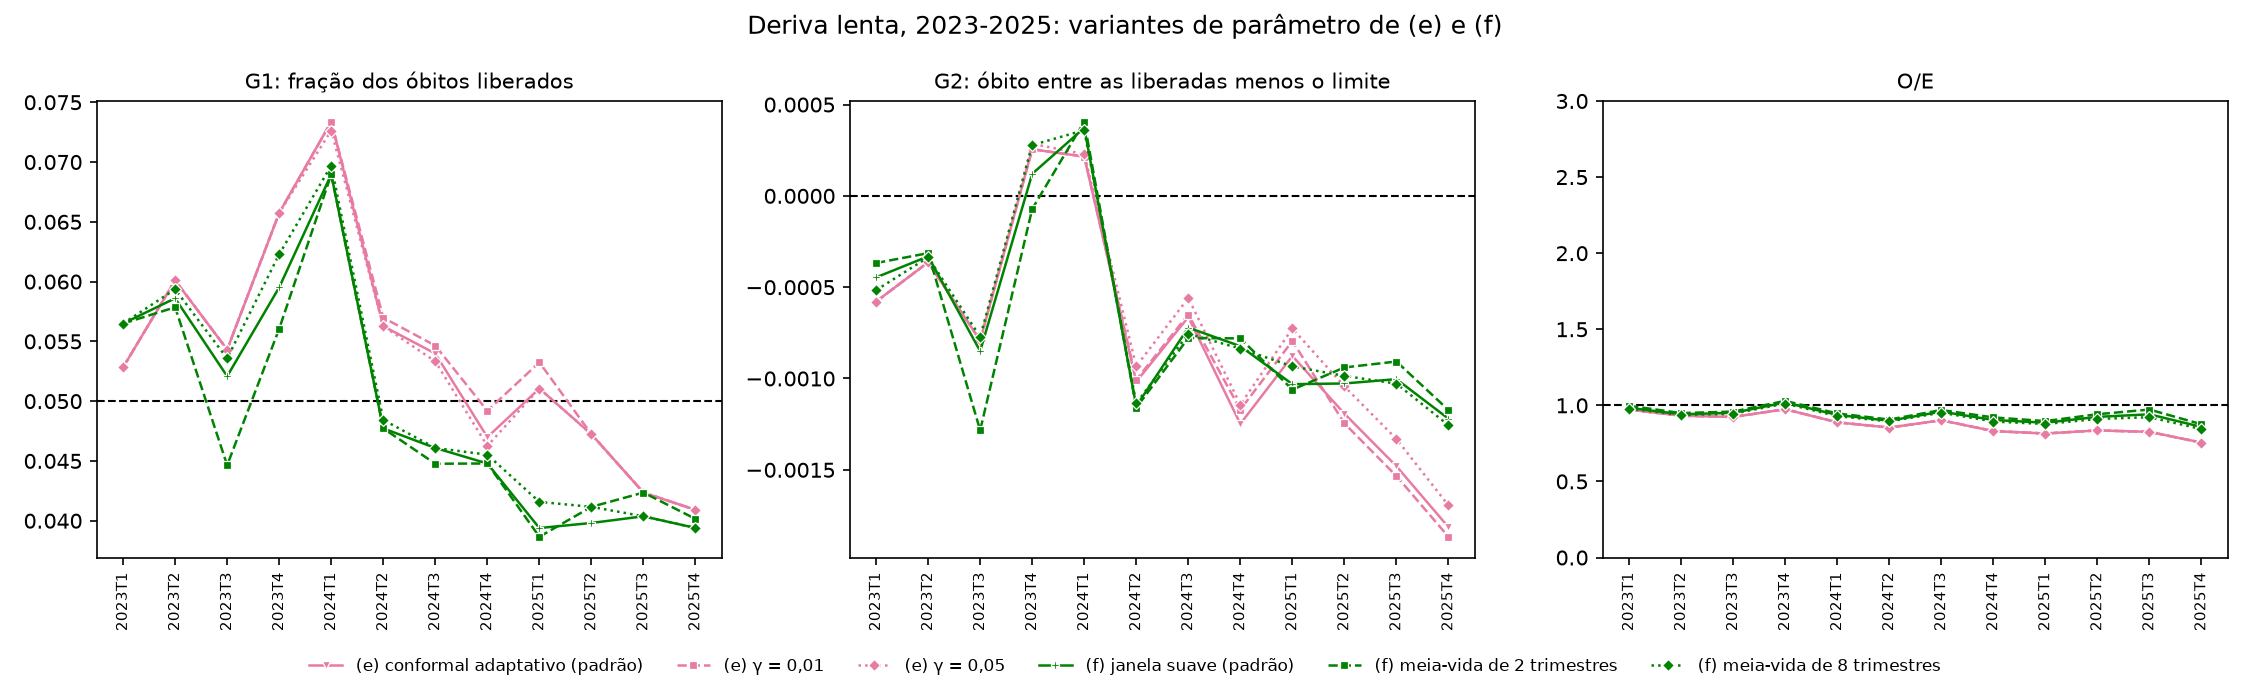

In [7]:
Image(filename=FIGURAS / "garantias_x3_parametros.png")

## A pandemia

No X4, o modelo foi treinado com as internações de janeiro a setembro de 2019 e calibrado com as de outubro a dezembro,
e os testes são os oito trimestres de 2020 e 2021. A (d) fica de fora: para 2020, ela teria de retreinar com internações
até 2018, anteriores à coorte. A tabela abaixo é a da estratégia estática.

In [8]:
por_trimestre(x4["a"])

,internações,razão de prevalência,liberadas,óbitos liberados,FDL,p G1,"p G1, Holm",TOL,r̂,"p G2, Holm",O/E
trimestre,,,,,,,,,,,
2020T1,24.289,"0,94","57,1%",50 de 1.043,"4,79%","0,5317","1,0000","0,36%","0,51%","1,0000","0,93"
2020T2,19.828,"1,21","52,6%",34 de 1.100,"3,09%","0,9664","1,0000","0,33%","0,51%","1,0000","1,06"
2020T3,21.203,"1,39","52,0%",46 de 1.343,"3,43%","0,9330","1,0000","0,42%","0,51%","1,0000","1,18"
2020T4,22.745,"1,24","54,6%",63 de 1.294,"4,87%","0,5024","1,0000","0,51%","0,51%","1,0000","1,14"
2021T1,22.740,"1,76","51,0%",57 de 1.826,"3,12%","0,9734","1,0000","0,49%","0,51%","1,0000","1,51"
2021T2,23.757,"1,50","48,2%",80 de 1.633,"4,90%","0,4885","1,0000","0,70%","0,51%","0,0392","1,28"
2021T3,25.055,"1,29","53,0%",51 de 1.481,"3,44%","0,9329","1,0000","0,38%","0,51%","1,0000","1,16"
2021T4,25.208,"1,10","56,5%",44 de 1.268,"3,47%","0,9244","1,0000","0,31%","0,51%","1,0000","1,05"


A razão de prevalência passou de 1,2 em seis dos oito trimestres e chegou a 1,76 em 2021T1. Mesmo assim, G1 aguentou: a
FDL da estática ficou entre 3,09% e 4,90%, e o menor p foi 0,4885. G2 falhou uma vez, em 2021T2, com TOL de 0,70% contra
um r̂ de 0,51% e p de 0,0392 depois de Holm. O O/E chegou a 1,51, agora com o modelo subestimando os óbitos.

In [9]:
por_estrategia("x4", x4)

,|O/E - 1| médio,trimestres com G1 violada,trimestres com G2 violada,"liberadas, média",FDL agregada,p do agregado,p do agregado sem surtos
estratégia,,,,,,,
(a) estática,"0,180",0,1,"53,1%","3,87%","0,8775","0,7812"
(b) anual,"0,148",0,1,"54,0%","4,33%","0,8229","0,7377"
(c) trimestral com atraso,"0,168",0,1,"54,1%","4,38%","0,8435","0,7895"
(e) conformal adaptativo,"0,180",0,1,"53,4%","4,00%","0,8391","0,7407"
(f) janela suave,"0,156",0,1,"54,7%","4,61%","0,7365","0,6759"
(g) correção de prevalência,"0,354",0,0,"53,1%","3,87%","0,8775","0,7812"
"(e) conformal adaptativo, γ=0,01","0,180",0,1,"53,1%","3,87%",-,-
"(e) conformal adaptativo, γ=0,05","0,180",0,1,"53,5%","4,04%",-,-
"(f) janela suave, meia-vida=2","0,159",0,1,"54,7%","4,64%",-,-


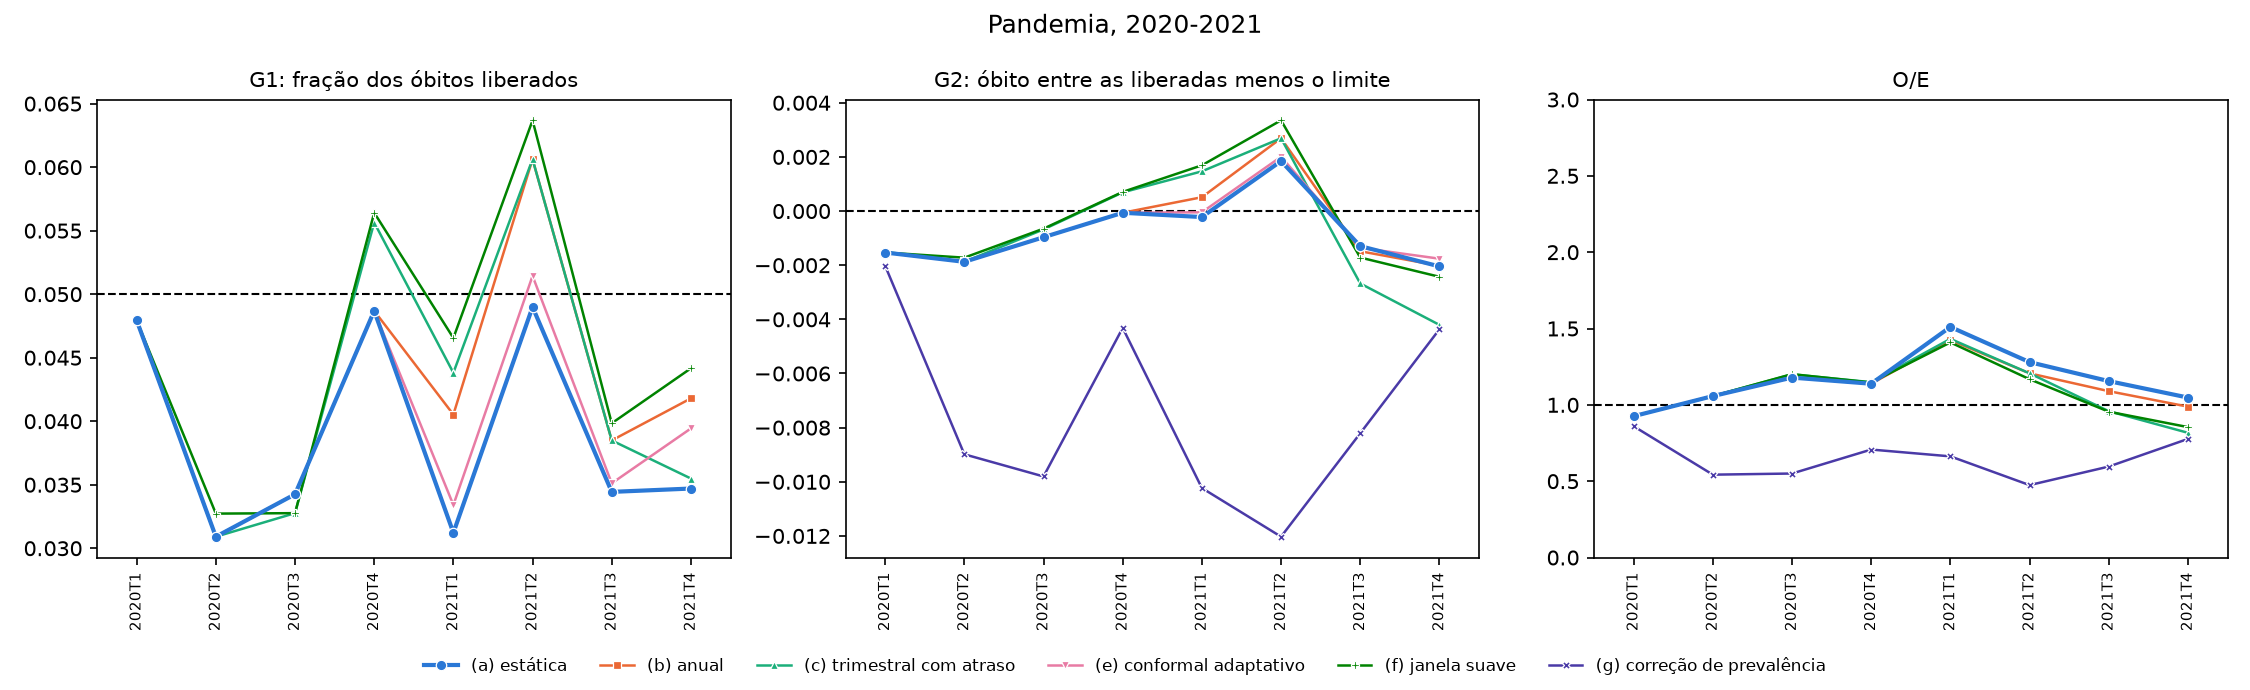

In [10]:
Image(filename=FIGURAS / "garantias_x4.png")

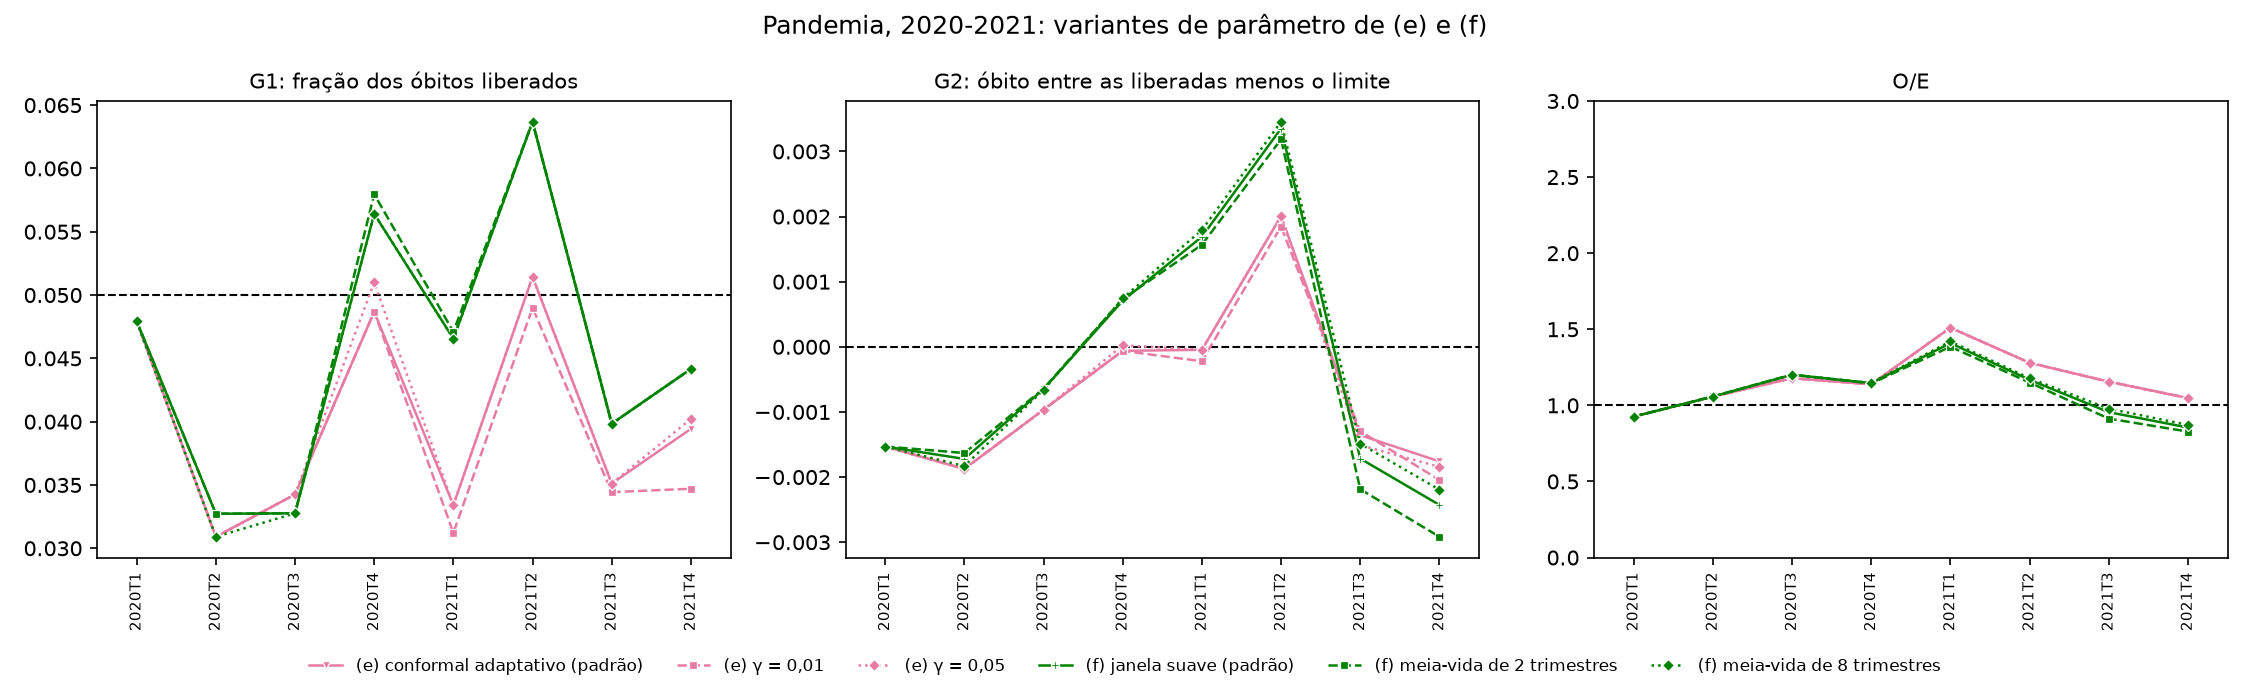

In [11]:
Image(filename=FIGURAS / "garantias_x4_parametros.png")

Nenhuma estratégia do X4 teve trimestre com G1 violada, e a FDL agregada ficou entre 3,87% e 4,64%. Todas menos a (g)
tiveram G2 violada em um trimestre, ou em dois, no caso da janela suave com meia-vida de 8 trimestres.

## Hipóteses exploratórias

O `resumo.json` aplica aos resultados de X3, X4 e X5 os critérios de H1, H1b, H2, H3 e H5. Cada cenário é um experimento
com uma estratégia, e x3_a, por exemplo, é a estática no X3. Os critérios de H2 nos exploratórios são os da função `h2`,
em `triagem_baixo_risco/avaliacao.py`: (i) menos da metade dos trimestres com razão de
prevalência de 1,2 ou mais tem G2 violada; (ii) nos trimestres com razão de até 1,0, G2 é violada ou a TOL agregada fica
acima do limite; (iii) a correlação de Spearman entre a razão e a TOL menos o r̂ não é positiva.

In [12]:
hip = resumo["hipoteses_exploratorias"]


def motivo_g1(v):
    return ", ".join(v["periodos_violados"] + (["agregado"] if v["agregado"]["p_violacao"] < 0.05 else []))


def motivo_g2(v):
    return ", ".join(c for c, x in zip(("i", "ii", "iii"), v["criterios"]) if x)


def onde(h, motivo):
    grupos = {}
    for cenario, v in h["cenarios"].items():
        if v["refuta"]:
            grupos.setdefault(motivo(v), []).append(cenario)
    return "; ".join(f"{', '.join(c)} ({m})" for m, c in grupos.items()) or "-"


h3, h5 = hip["h3"], hip["h5"]["faixas"]
linhas = {
    "H1": (hip["h1"]["refutada"], onde(hip["h1"], motivo_g1)),
    "H1b": (hip["h1b"]["refutada"], onde(hip["h1b"], motivo_g1)),
    "H2": (hip["h2"]["refutada"], onde(hip["h2"], motivo_g2)),
    "H3": (h3["refutada"], f"Wilcoxon p = {pv(h3['p_wilcoxon'])}; McNemar p = {pv(h3['p_mcnemar'])}"),
    "H5": (hip["h5"]["refutada"], ", ".join(f for f, v in h5.items() if v.get("refuta")) or "-"),
}
pd.DataFrame({h: {"refutada": "sim" if r else "não", "onde": o} for h, (r, o) in linhas.items()}).T

,refutada,onde
H1,sim,"x3_a, x3_e, x3_g (2024T1)"
H1b,não,-
H2,sim,"x3_b (iii); x3_g (ii); x4_a, x4_b, x4_c, x4_e, x4_f (i); x4_g (i, iii)"
H3,não,"Wilcoxon p = 0,0065; McNemar p = 1,0000"
H5,não,-


H1 é refutada só pelo 1º trimestre de 2024, nas três estratégias que ficam com a calibração de 2022: (a), (e) e (g). Sem
os óbitos de A90, esse trimestre deixa de violar G1, e H1b não é refutada em cenário nenhum.

A refutação de H2 vem de mais de um critério. Na pandemia, com razão de prevalência de 1,2 ou mais, G2 falhou em no
máximo um trimestre em cada estratégia de (a) a (g), bem menos que a metade que H2 previa (critério i). Em 2023-2025, a
(g) passou do limite nos trimestres de razão baixa (ii), e a (b) não mostrou correlação positiva entre a razão e o
excesso de TOL (iii). G2 foi menos frágil do que eu esperava.

Para H3, a recalibração trimestral ganha da estática no |O/E - 1|, com p = 0,0065 no Wilcoxon, mas não nas violações de
G2 (McNemar p = 1,0000), e basta um dos dois para H3 não ser refutada. H5 depende do X5 e está no notebook 3.0.